# Appendix A: critical confidence, Fig. A.1

The proposed index is at least the standard one, $\tilde m\geq m^*$, for every $N_\mathrm{cal}$ if and only if $1-\alpha\geq\gamma^*(C^\mathrm{min})$, the largest over $N_\mathrm{cal}$ of $\mathbb P(K\leq m^*-2)$ with $K\sim\mathrm{Bin}(N_\mathrm{cal},C^\mathrm{min})$ (computed here for $N_\mathrm{cal}\leq10^4$). Runs in less than a minute.

In [1]:
import math
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st

import reliable_conformal_prediction as rcp

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import cp_plot as cpl  # noqa: E402

FIG = HERE / "figures"
warnings.simplefilter("ignore", rcp.InfeasibleRequestWarning)  # below the minimum size, the index is N_cal + 1 (trivial set)

NMAX = 10_000
N_ALL = np.arange(1, NMAX + 1)
J = np.arange(500, 1000)  # C_min = J / 1000


index_standard = np.vectorize(rcp.get_index_standard)  # the package function takes one calibration size at a time


def gamma_int(j):
    # critical confidence F_K(m* - 2), K ~ Bin(N, j/1000), for N = 1..NMAX
    m_std = index_standard(N_ALL, j / 1000)
    return st.binom.cdf(m_std - 2, N_ALL, j / 1000)


# supremum over N; it is at least 1/2, the limit as N grows
gstar = pd.DataFrame([dict(C_min=j / 1000, gamma_star=max(0.5, gamma_int(j).max())) for j in J])

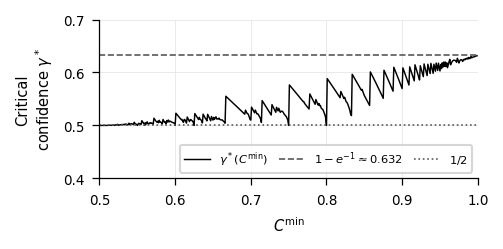

In [2]:
REF = dict(color=cpl.COL["oracle"], lw=0.8)
with cpl.style():
    fig, b = plt.subplots(figsize=(0.6 * cpl.TEXT_WIDTH, 1.55), constrained_layout=True)
    b.plot(gstar.C_min, gstar.gamma_star, color="k", lw=0.7, label="$\\gamma^*(C^{\\min})$")
    b.axhline(1 - math.exp(-1), ls="--", **REF, label="$1-e^{-1}\\approx0.632$")
    b.axhline(0.5, ls=":", **REF, label="$1/2$")
    b.set(xlim=(0.5, 1), ylim=(0.4, 0.7), xlabel="$C^{\\min}$", ylabel="Critical\nconfidence $\\gamma^*$")
    b.legend(loc="lower right", fontsize=5.5, ncol=3, columnspacing=1.0)
    cpl.savefig(fig, "fig_critical_confidence", figdir=FIG)
plt.show()